In [1]:
import glob
import xarray as xr

In [2]:
DATA_DIR = r"C:\Users\giorg\Desktop\290A\Project1_WeatherPrediction\data\data"

temp_files = sorted(
    glob.glob(f"{DATA_DIR}/**/2m_temperature*.nc", recursive=True)
)

ds_temp = xr.open_mfdataset(temp_files, combine="by_coords")
T2M = ds_temp["t2m"]

T2M

<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<concatenate, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0

Convert temp units from Kelvin to Celcius

In [3]:
T2M_C = T2M - 273.15
T2M_C.attrs["units"] = "degC"

T2M_C

<xarray.DataArray 't2m' (valid_time: 730, latitude: 105, longitude: 237)> Size: 73MB
dask.array<sub, shape=(730, 105, 237), dtype=float32, chunksize=(62, 105, 237), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [4]:
day0 = T2M_C.isel(valid_time=0)

day0

<xarray.DataArray 't2m' (latitude: 105, longitude: 237)> Size: 100kB
dask.array<getitem, shape=(105, 237), dtype=float32, chunksize=(105, 237), chunktype=numpy.ndarray>
Coordinates:
  * latitude    (latitude) float64 840B 50.0 49.75 49.5 ... 24.5 24.25 24.0
  * longitude   (longitude) float64 2kB -125.0 -124.8 -124.5 ... -66.25 -66.0
    number      int64 8B 0
    valid_time  datetime64[ns] 8B 2009-01-01
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

Text(0.5, 1.0, 'Daily Mean Temperature — January 1, 2009')

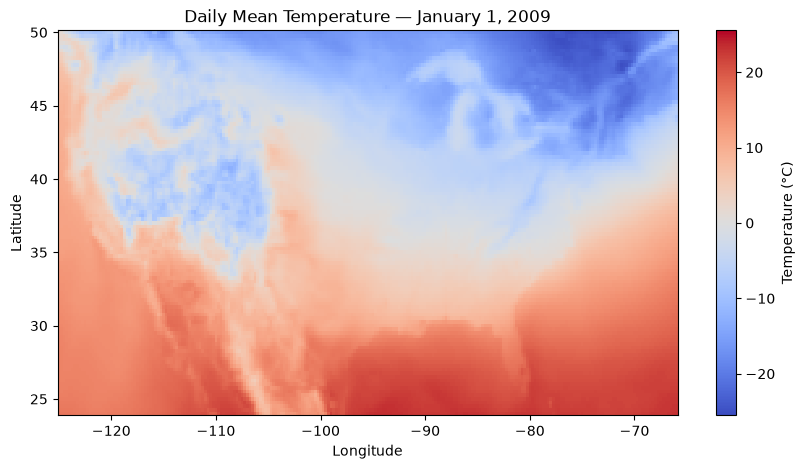

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))

day0.plot(
    ax=ax,
    cmap="coolwarm",
    cbar_kwargs={"label": "Temperature (°C)"}
)

ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Daily Mean Temperature — January 1, 2009")

On January 1, 2009, temperatures were generally lower in the northern part of the region and higher in the southern part.

Text(0.5, 1.0, 'Temperature Along 33.75°N — January 1, 2009')

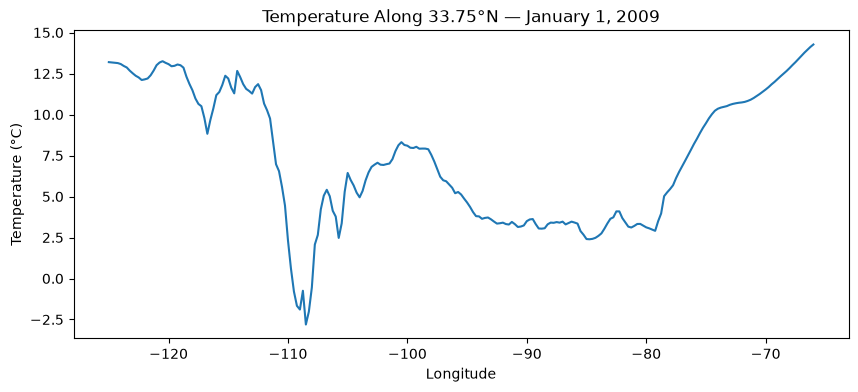

In [6]:
temp_line = day0.sel(latitude=33.75, method="nearest")

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(temp_line["longitude"], temp_line)

ax.set_xlabel("Longitude")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature Along 33.75°N — January 1, 2009")

Text(0.5, 1.0, 'Temperature Along 117.75°W — January 1, 2009')

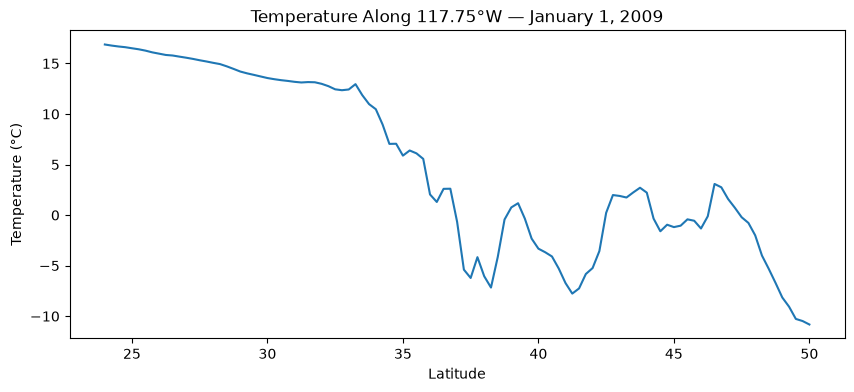

In [8]:
temp_ns = day0.sel(longitude=-117.75, method="nearest")

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(temp_ns["latitude"], temp_ns)

ax.set_xlabel("Latitude")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature Along 117.75°W — January 1, 2009")

On January 1, 2009, I compared temperature along two lines crossing the grid point near Irvine (33.75°N, 117.75°W).
- West to east, along 33.75°N: Temperature varied considerably, with a minimum of about −3°C near 108°W. However, there was no consistent increasing or decreasing trend.
- South to north, along 117.75°W: Temperature generally decreased, from about 17°C in the south to −11°C in the north, although there were several local rises and falls.
For these two lines on this day, the north–south pattern showed a clearer overall trend and a larger temperature range. These plots compare different locations, not temperature changes over time at Irvine.

In [9]:
T_irvine = T2M_C.sel(
    latitude=33.75,
    longitude=-117.75,
    method="nearest"
)

T_irvine

<xarray.DataArray 't2m' (valid_time: 730)> Size: 3kB
dask.array<getitem, shape=(730,), dtype=float32, chunksize=(62,), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
    number      int64 8B 0
    latitude    float64 8B 33.75
    longitude   float64 8B -117.8
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

Text(0.5, 1.0, 'Daily Mean Temperature Near Irvine — 2009–2010')

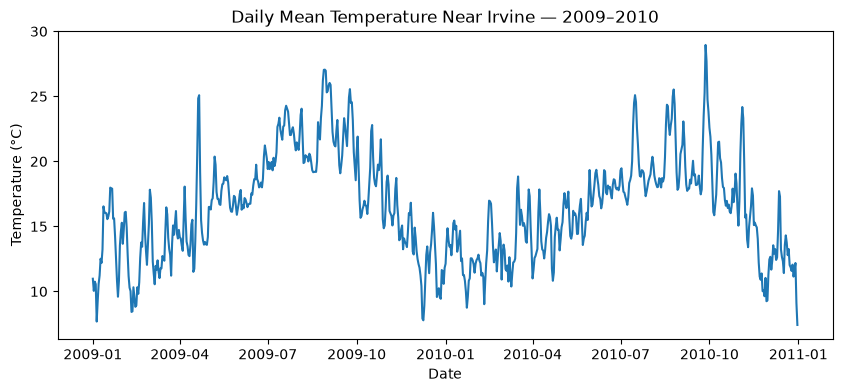

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(T_irvine["valid_time"], T_irvine)

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Daily Mean Temperature Near Irvine — 2009–2010")

Daily mean temperature near Irvine was generally higher in summer and lower in winter during 2009–2010. There were also noticeable day-to-day fluctuations within this seasonal pattern.

In [11]:
T_irvine_3day = T_irvine.rolling(valid_time=3).mean()

T_irvine_3day

<xarray.DataArray 't2m' (valid_time: 730)> Size: 3kB
dask.array<truediv, shape=(730,), dtype=float32, chunksize=(62,), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
    number      int64 8B 0
    latitude    float64 8B 33.75
    longitude   float64 8B -117.8
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

In [12]:
T_irvine_7day = T_irvine.rolling(valid_time=7).mean()

T_irvine_7day

<xarray.DataArray 't2m' (valid_time: 730)> Size: 3kB
dask.array<truediv, shape=(730,), dtype=float32, chunksize=(65,), chunktype=numpy.ndarray>
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 6kB 2009-01-01 ... 2010-12-31
    number      int64 8B 0
    latitude    float64 8B 33.75
    longitude   float64 8B -117.8
Attributes: (12/32)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      24885
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               K
    long_name:                                2 metre temperature
    units:                                    degC
    standard_name:                            unknown
    GRIB_surface:                             0.0

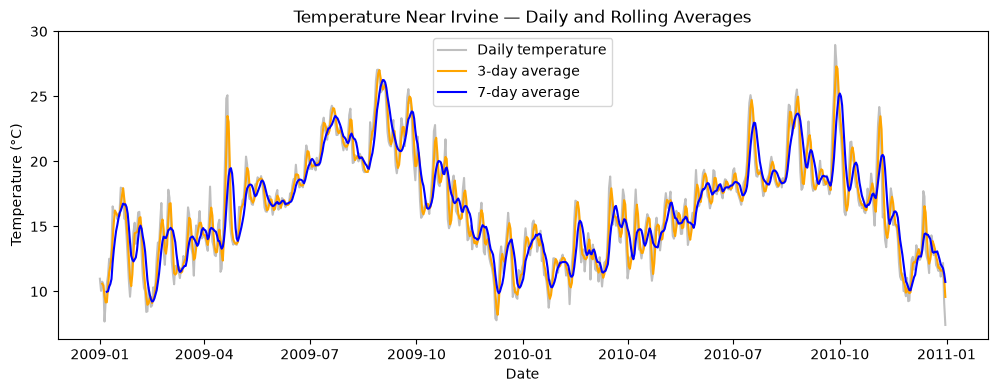

In [13]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(T_irvine["valid_time"], T_irvine,
        color="gray", alpha=0.5, label="Daily temperature")

ax.plot(T_irvine_3day["valid_time"], T_irvine_3day,
        color="orange", label="3-day average")

ax.plot(T_irvine_7day["valid_time"], T_irvine_7day,
        color="blue", label="7-day average")

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Temperature Near Irvine — Daily and Rolling Averages")
ax.legend()

The 7-day average is smoother than the 3-day average because it averages over more days. Both reduce day-to-day fluctuations while preserving the seasonal pattern, but the 7-day average responds more slowly to sudden temperature changes.

In [15]:
import pandas as pd

# Create a daily temperature table for the persistence baseline.
df = pd.DataFrame({
    "today_temp": T_irvine.to_series()
})

df.head()

,today_temp
valid_time,
2009-01-01,10.976807
2009-01-02,10.043762
2009-01-03,10.752289
2009-01-04,10.557648
2009-01-05,7.683075


In [17]:
# Use the next day's observed temperature as the prediction target.
df["tomorrow_temp"] = df["today_temp"].shift(-1)

df.head()

,today_temp,tomorrow_temp
valid_time,,
2009-01-01,10.976807,10.043762
2009-01-02,10.043762,10.752289
2009-01-03,10.752289,10.557648
2009-01-04,10.557648,7.683075
2009-01-05,7.683075,9.233704


In [18]:
# Predict tomorrow's temperature using today's observed temperature.
df["persistence_pred"] = df["today_temp"]

# Compare the prediction with tomorrow's actual temperature.
df[["today_temp", "tomorrow_temp", "persistence_pred"]].head()

,today_temp,tomorrow_temp,persistence_pred
valid_time,,,
2009-01-01,10.976807,10.043762,10.976807
2009-01-02,10.043762,10.752289,10.043762
2009-01-03,10.752289,10.557648,10.752289
2009-01-04,10.557648,7.683075,10.557648
2009-01-05,7.683075,9.233704,7.683075


In [19]:
df.tail()

,today_temp,tomorrow_temp,persistence_pred
valid_time,,,
2010-12-27,11.141174,11.606323,11.141174
2010-12-28,11.606323,12.185303,11.606323
2010-12-29,12.185303,9.120850,12.185303
2010-12-30,9.120850,7.422546,9.120850
2010-12-31,7.422546,NaN,7.422546


In [20]:
# Keep only rows with an observed next-day temperature.
df_model = df.dropna(subset=["tomorrow_temp"]).copy()

In [21]:
# Check the number of rows before and after removing the missing target.
print("Original rows:", len(df))
print("Rows with a target:", len(df_model))

Original rows: 730
Rows with a target: 729


In [22]:
# Record the date of the temperature we are predicting.
df_model["target_date"] = df_model.index + pd.Timedelta(days=1)

In [23]:
# Check that each target date is one day after the observation date.
df_model[["target_date", "today_temp", "tomorrow_temp"]].head()

,target_date,today_temp,tomorrow_temp
valid_time,,,
2009-01-01,2009-01-02,10.976807,10.043762
2009-01-02,2009-01-03,10.043762,10.752289
2009-01-03,2009-01-04,10.752289,10.557648
2009-01-04,2009-01-05,10.557648,7.683075
2009-01-05,2009-01-06,7.683075,9.233704


I plan to use targets before 2010 for training, and then use targets from January through June 2010 for validation. Fianlly, reserve targets from July 2010 onward for the final test.

In [24]:
train = df_model[df_model["target_date"] < "2010-01-01"].copy()

In [25]:
validation = df_model[
    (df_model["target_date"] >= "2010-01-01") &
    (df_model["target_date"] < "2010-07-01")
].copy()

In [26]:
test = df_model[df_model["target_date"] >= "2010-07-01"].copy()

In [27]:
print("Training:", len(train))
print("Validation:", len(validation))
print("Test:", len(test))

Training: 364
Validation: 181
Test: 184


I will calculate two measures:

- MAE: the average absolute difference between predicted and actual temperatures.
- RMSE: the square root of the average squared error. It gives more weight to large errors.

Both measures are in degrees Celsius, and lower values mean smaller prediction errors.

These results will provide a baseline for comparison with linear regression on the same validation dates. The test set will remain unused until the final model is selected.

In [28]:
errors = validation["persistence_pred"] - validation["tomorrow_temp"]

mae = errors.abs().mean()

print("Persistence validation MAE:", mae)

Persistence validation MAE: 0.90098965


In [29]:
mse = (errors ** 2).mean()

rmse = mse ** 0.5

print("Persistence validation RMSE:", rmse)

Persistence validation RMSE: 1.1478524


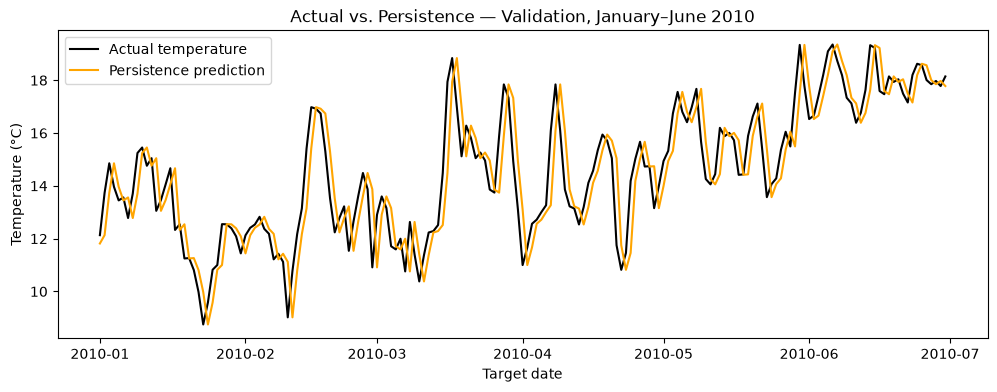

In [32]:
fig, ax = plt.subplots(figsize=(12, 4))

ax.plot(validation["target_date"], validation["tomorrow_temp"],
        color="black", label="Actual temperature")

ax.plot(validation["target_date"], validation["persistence_pred"],
        color="orange", label="Persistence prediction")

ax.set_xlabel("Target date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Actual vs. Persistence — Validation, January–June 2010")
ax.legend()

On the January–June 2010 validation set, persistence achieved an MAE of 0.90°C and an RMSE of 1.15°C. The predictions followed the actual temperature pattern but lagged by one day. Errors were larger when temperature changed sharply. These results provide a baseline for evaluating linear regression on the same validation dates.

In [33]:
X_train = train[["today_temp"]]

y_train = train["tomorrow_temp"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

X_train shape: (364, 1)
y_train shape: (364,)


In [34]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression()

reg.fit(X_train, y_train)

print("Slope:", reg.coef_[0])
print("Intercept:", reg.intercept_)

Slope: 0.953983
Intercept: 0.7772236


In [35]:
X_val = validation[["today_temp"]]

validation["linear_pred"] = reg.predict(X_val)

validation[["tomorrow_temp", "persistence_pred", "linear_pred"]].head()

,tomorrow_temp,persistence_pred,linear_pred
valid_time,,,
2009-12-31,12.131531,11.815826,12.049321
2010-01-01,13.732849,12.131531,12.350498
2010-01-02,14.855377,13.732849,13.878128
2010-01-03,13.962616,14.855377,14.949001
2010-01-04,13.447449,13.962616,14.097322


In [36]:
# Calculate linear regression errors on the validation set.
linear_errors = validation["linear_pred"] - validation["tomorrow_temp"]

linear_mae = linear_errors.abs().mean()
linear_rmse = ((linear_errors ** 2).mean()) ** 0.5

print("Persistence MAE:", mae)
print("Linear regression MAE:", linear_mae)

print("Persistence RMSE:", rmse)
print("Linear regression RMSE:", linear_rmse)

Persistence MAE: 0.90098965
Linear regression MAE: 0.87300825
Persistence RMSE: 1.1478524
Linear regression RMSE: 1.1292427


Using today's temperature to predict tomorrow's temperature, linear regression achieved a validation MAE of 0.873°C and an RMSE of 1.129°C.

Both errors were slightly lower than persistence: MAE decreased by about 3.1% and RMSE by about 1.6%. This suggests a small improvement on this validation period. The test set has not been evaluated.